<a href="https://colab.research.google.com/github/0110225150-hub/Nunaaaaa/blob/main/02_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Pembersihan Data
### Milestone M2 · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | Nunaaa |
| **Anggota** | Salma Haniya Rahma (0110225150)
| | Trisa Dhiya Nasywa (0110225049) |
| | Labibah Nurrahmah (0110225176) |
| | Indah Nurul Ayni (0110225121) |
| **Topik proyek** | Analisis Pola Penjualan Toko Ritel |
| **Tanggal** | 15 November 2026 |

**Notebook ini mengisi:** dimensi **Justifikasi keputusan cleaning** (30), **Ketepatan implementasi** (20), dan **Dokumentasi dan keterlacakan** (15) pada Rubrik M2.

Dimensi dengan bobot terbesar di M2 bukan kode yang benar, melainkan **alasan** di balik
setiap keputusan. Untuk setiap langkah, tuliskan tiga hal: apa yang dilakukan, mengapa,
dan apa dampaknya terhadap data.

Urutan langkah di notebook ini harus sama dengan urutan di `cleaning_log.md`.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**. Notebook yang tidak dapat
> berjalan dari awal sampai akhir dianggap tidak memenuhi dimensi *ketepatan implementasi*.

In [43]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from google.colab import drive

# Menghubungkan Google Drive ke Colab
drive.mount('/content/drive')

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 60)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

DATA  = '#0E7490'   # warna utama
SOROT = '#C2410C'   # penyorot
REDUP = '#5B6672'

AKAR      = Path('/content/drive/MyDrive/EDA 2026/Proyek tim/Proyek tim')
RAW       = AKAR / 'data' / 'raw'
PROCESSED = AKAR / 'data' / 'processed'
FIGURES   = AKAR / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Muat ulang data mentah

Selalu mulai dari `data/raw`, bukan dari hasil pembersihan sebelumnya. Dengan begitu
notebook ini dapat dijalankan ulang kapan saja dan memberi hasil yang sama.

In [44]:
BERKAS = RAW / 'retail_store_sales.csv'

assert BERKAS.exists(), (
    f'Berkas tidak ditemukan: {BERKAS}\n'
    'Periksa apakah data sudah diletakkan di data/raw dan namanya sudah benar.'
)

df = pd.read_csv(BERKAS)

# Menggunakan df_info sebagai df utama untuk analisis awal di bawah
print(f'{df.shape[0]} baris x {df.shape[1]} kolom')
df.head()

12575 baris x 11 kolom


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [45]:
df_raw = pd.read_csv(BERKAS)
df = df_raw.copy()                        # bekerja pada salinan
print(f'baris awal: {len(df_raw)}')

baris awal: 12575


## Langkah 1 — Ubah tipe data

---


**Apa:** 3 kolom diubah tipenya. `Transaction Date` menjadi tanggal, `Discount Applied` menjadi boolean yang boleh kosong, dan `Quantity` menjadi bilangan bulat yang boleh kosong.\
**Mengapa:** Tanggal yang tadinya masih berupa teks tidak bisa diurutkan atau dikelompokkan perbulan/tahun. `Discount Applied` berisi campuran True, False, dan kosong di kolom `Object`. `Quantity` = jumlah barang, harusnya berbentuk bilangan bulat, bukan 5,0. Format tanggal di data adalah YYYY-MM-DD, dipakai menjadi format='%Y-%m-%d'.\
**Alternatif yang dipertimbangkan:**
- membiarkan tanggal sebagai teks - tidak dipilih karena analisis perbulan/tahun jadi sulit atau rawan salah.
- mengubah diskon menjadi 0/1 - tidak dipilih karena nilai kosong akan berubah menjadi 0 (dianggap tanpa diskon), padahal tidak diketahui.

In [46]:
log = []    # catatan setiap langkah, nanti diekspor ke cleaning_log.md
def catat(langkah, alasan, sebelum, sesudah, terdampak=0):
    log.append({'langkah': langkah, 'alasan': alasan,
                'baris_sebelum': sebelum, 'baris_sesudah': sesudah,
                'selisih': sesudah - sebelum, 'terdampak': terdampak})
    print(f'[{len(log):02d}] {langkah}: {sebelum} -> {sesudah} baris ({sesudah-sebelum:+d}), terdampak: {terdampak}')

In [47]:
n0 = len(df)

df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], format='%Y-%m-%d')
df['Discount Applied'] = df['Discount Applied'].astype('boolean')
df['Quantity']         = df['Quantity'].astype('Int64')

catat('Ubah tipe data (tanggal, diskon, jumlah)',
      'Tipe lama tidak sesuai arti kolom; nilai tidak berubah', n0, len(df), terdampak='3 kolom')

[01] Ubah tipe data (tanggal, diskon, jumlah): 12575 -> 12575 baris (+0), terdampak: 3 kolom


In [48]:
# Bukti: tipe berubah, nilainya tetap sama (untuk pengecekan bukti aja)
kolom = ['Transaction Date', 'Discount Applied', 'Quantity']
print(pd.DataFrame({'sebelum': df_raw[kolom].dtypes.astype(str), 'sesudah': df[kolom].dtypes.astype(str)}).to_string())

print('\nQuantity: nilai sama persis ->',
      np.array_equal(df_raw['Quantity'].dropna().to_numpy(), df['Quantity'].dropna().to_numpy(dtype='float64')))
print('Discount Applied sebelum :', df_raw['Discount Applied'].value_counts(dropna=False).to_dict())
print('Discount Applied sesudah :', df['Discount Applied'].value_counts(dropna=False).to_dict())
print('Rentang tanggal          :', df['Transaction Date'].min().date(), 'sampai', df['Transaction Date'].max().date())

                  sebelum         sesudah
Transaction Date   object  datetime64[ns]
Discount Applied   object         boolean
Quantity          float64           Int64

Quantity: nilai sama persis -> True
Discount Applied sebelum : {True: 4219, nan: 4199, False: 4157}
Discount Applied sesudah : {np.True_: 4219, <NA>: 4199, np.False_: 4157}
Rentang tanggal          : 2022-01-01 sampai 2025-01-18


## Langkah 2 — Hitung ulang `Price Per Unit` yang kosong

**Apa:** Pada 609 baris `Price Per Unit` kosong, harga diisi dengan `Total Spent` / `Quantity`.
**Mengapa:** Di M1 (01_quality.ipynb) terbukti bahwa `Total Spent` = `Price Per Unit` x `Quantity`berlaku di semua 11.362 baris yang lengkap (0 pengecualian). Pada 609 baris ini `Quantity` dan `Total Spent` terisi, jadi harganya bisa dihitung dengan pasti, bukan ditebak.
**Alternatif yang dipertimbangkan:**
- mengisi dengan mean atau median harga - tidak tipilih karena menebak padahal nilai pastinya bisa dihitung, dan merusak hubungan Total = Harga x Jumlah.
- membuang 609 baris nya - tidak dipilih karena membuang 4,84% data tanpa perlu.

In [49]:
n0 = len(df)

qty = df['Quantity'].to_numpy(dtype='float64', na_value=np.nan)
harga_hitung = (df['Total Spent'] / qty).round(2)
kosong_harga = df['Price Per Unit'].isna()

assert harga_hitung[kosong_harga].notna().all(), 'ada harga kosong yang tidak bisa dihitung'
df.loc[kosong_harga, 'Price Per Unit'] = harga_hitung[kosong_harga]

catat('Hitung Price Per Unit dari Total Spent / Quantity',
      'Rumus Total = Harga x Jumlah berlaku di semua baris lengkap', n0, len(df),
      terdampak=int(kosong_harga.sum()))

[02] Hitung Price Per Unit dari Total Spent / Quantity: 12575 -> 12575 baris (+0), terdampak: 609


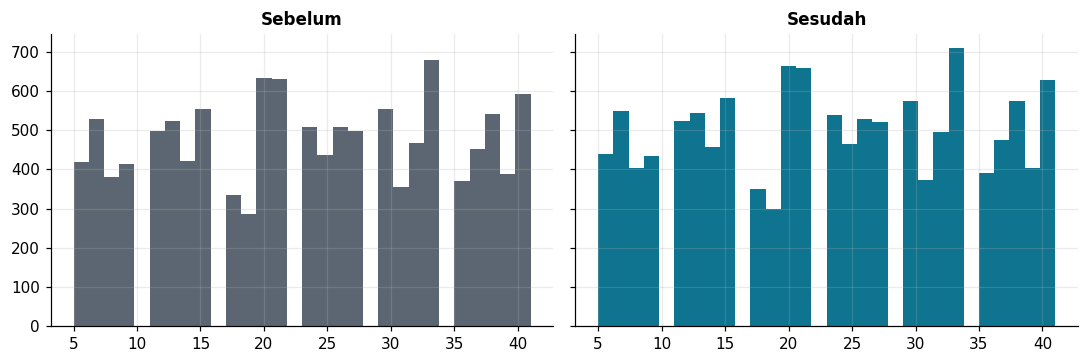

Terisi : 11966 -> 12575
Rata-rata: 23.37 -> 23.37   |   simpangan baku: 10.74 -> 10.75


In [50]:
KOL = 'Price Per Unit'
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True, sharey=True)
bins = np.histogram_bin_edges(df_raw[KOL].dropna(), bins=30)
ax[0].hist(df_raw[KOL].dropna(), bins=bins, color=REDUP); ax[0].set_title('Sebelum')
ax[1].hist(df[KOL].dropna(),     bins=bins, color=DATA);  ax[1].set_title('Sesudah')
plt.tight_layout(); plt.show()
fig.savefig(FIGURES / '02_sebaran_harga.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Terisi : {df_raw[KOL].notna().sum()} -> {df[KOL].notna().sum()}")
print(f"Rata-rata: {df_raw[KOL].mean():.2f} -> {df[KOL].mean():.2f}   |   simpangan baku: {df_raw[KOL].std():.2f} -> {df[KOL].std():.2f}")

## Langkah 3 — Pulihkan `Item` yang kosong dari `Category` dan harga

**Apa:** Pada 1.213 baris yang `Item` nya kosong, `Item` diisi memakai tabel acuan pasangan (`Category`, `Price Per Unit`) -> `Item`. Tabel acuan dibuat dari baris yang aslinya lengkap.\
**Mengapa:** Di data ini setiap pasangan (Category, harga) cocok ke tepat satu Item (200 pasangan, 0 yang bentrok), dan saat diuji pada Item yang sudah terisi, hasil acuan cocok 100%. Jadi Item bisa dipulihkan dengan pasti. Item kosong tepat di baris `Price` atau `Quantity` nya kosong, jadi kosongnya bukan acakk dan justru karena itu mudah dipulihkan.\
**Alternatif yang dipertimbangkan:**
- memberi label "unknown" - tidak dipilih karena membuang informasi yang sebenarnya bisa dipulihkan.
- mengisi dengan Item paling sering di kategori itu - tidak dipilih karena menebak, dan hampir pasti salah (ada 25 Item per kategori)
- membuang baris - tidak dipilih karena membuang 9,65% data.

In [51]:
n0 = len(df)

# tabel acuan dari baris yang aslinya lengkap
acuan = df_raw.dropna(subset=['Item', 'Price Per Unit'])[['Category', 'Price Per Unit', 'Item']].drop_duplicates()
assert acuan.groupby(['Category', 'Price Per Unit'])['Item'].nunique().max() == 1, 'satu pasangan cocok ke > 1 Item'

hasil = df[['Category', 'Price Per Unit']].merge(acuan, how='left', on=['Category', 'Price Per Unit'])['Item']
hasil.index = df.index
kosong_item = df['Item'].isna()

assert hasil[kosong_item].notna().all(), 'ada Item kosong yang tidak bisa dipulihkan'
assert (hasil[~kosong_item] == df.loc[~kosong_item, 'Item']).all(), 'acuan tidak cocok dengan Item yang sudah terisi'
df.loc[kosong_item, 'Item'] = hasil[kosong_item]

catat('Pulihkan Item dari Category + Price Per Unit',
      'Satu pasangan (Category, harga) = satu Item; cocok 100% pada data lengkap', n0, len(df),
      terdampak=int(kosong_item.sum()))

[03] Pulihkan Item dari Category + Price Per Unit: 12575 -> 12575 baris (+0), terdampak: 1213


In [52]:
# Bukti dampak (untuk pengecekan bukti aja)
print('Item terisi          :', df_raw['Item'].notna().sum(), '->', df['Item'].notna().sum())
print('Jumlah Item berbeda  :', df_raw['Item'].nunique(), '->', df['Item'].nunique(), '(tetap 200, tidak ada Item baru)')
print('\nContoh baris yang dipulihkan:')
print(df.loc[kosong_item, ['Category', 'Price Per Unit', 'Item']].head(5).to_string())

Item terisi          : 11362 -> 12575
Jumlah Item berbeda  : 200 -> 200 (tetap 200, tidak ada Item baru)

Contoh baris yang dipulihkan:
         Category  Price Per Unit          Item
5      Patisserie            20.0   Item_11_PAT
7       Furniture            33.5   Item_20_FUR
11  Milk Products             6.5   Item_2_MILK
15      Beverages            24.5   Item_14_BEV
17  Milk Products            27.5  Item_16_MILK


_Salin blok di atas untuk langkah-langkah berikutnya._

## Penanganan nilai yang hilang

Keputusan ini dinilai paling ketat. Dasarkan pada **mekanisme** kekosongan yang Anda
temukan di `01_quality.ipynb`, bukan pada kemudahan.

| Mekanisme | Artinya | Penanganan yang biasanya sesuai |
|---|---|---|
| MCAR | kekosongan acak sepenuhnya | boleh dibuang; bias kecil |
| MAR | kekosongan dijelaskan kolom lain yang teramati | imputasi dengan prediktor, atau analisis terpisah |
| MNAR | kekosongan bergantung pada nilai yang tidak terlihat | **jangan** diisi rata-rata; laporkan dan batasi klaim |

Perlu diingat: MAR dan MNAR **tidak dapat dibedakan** hanya dari data. Nyatakan asumsi
yang Anda pakai secara terbuka.

## Mekanisme kekosongan dari tiap kolom (dari file M1)

| Kolom | Kosong | Mekanisme | Dasar | Penanganan |
|---|---|---|---|---|
| `Item` | 1.213 baris | Dijelaskan kolom lain: kosong tepat saat Price atau Quantity kosong | Pola di M1 | Dipulihkan pasti (langkah 3) |
| `price Per Unit` | 609 baris | Dijelaskan hubungan rumus Total = Harga x Jumlah | Cek akurasi di M1 | Dihitung ulang (langkah 2) |
| `Quantity` dan `Total Spent` | 604 baris | Tampak MCAR (acak) | Sel diuji di bawah | Dibiarkan kosong dan ditandai (langkah 4) |
| `Discount Applied` | 4.199 baris | Tampak MCAR (acak) | Sel diuji di bawah | Diberi label "Tidak Diketahui" (langkah 5) |

kosongnya `Discount Applied` punya hubungan tipis dengan `Category` (p=0,023). Hubungan ini lemah (persentase kosong hanya 31-26% di semua kategori) dan muncul diantara 6 uji, jadi bisa aja kebetulan. kesimpulan "tampak acak" tetap dipakai, tetapi dicatat disini.\

Asumsi: MCAR, MAR, dan MNAR tidak bisa dibedakan dari data. "tampak acak" disini berarti tidak bisa ditemukan hubungan antara kekosongan dan kolom lain yang ada.\
Kemnugkinan kosong karena alasan yang tidak tercatat tidak bisa dibuktikan salah. Karena itu klaim analisis nanti dibatasi: hasil yang memakai Quantity/Total atau Discount hanya berlaku untuk baris yang datanya diketahui.

## Langkah 4 — Tandai baris Quantity/Total yang kosong, jangan diisi

**Apa:** `Quantity` dan `Total Spent` yang kosong (604 baris) **dibiarkan kosong**. Ditambahkan kolom
`Penjualan Lengkap` (True bila `Quantity` dan `Total Spent` keduanya terisi) supaya baris itu mudah
dikeluarkan saat menghitung jumlah barang atau pendapatan. Barisnya tetap disimpan.\

**Mengapa:** Nilainya **tidak bisa dihitung**: `Quantity` dan `Total Spent` hilang bersamaan, jadi
rumus Total = Harga × Jumlah tidak punya satu pun nilai untuk dipakai. Kosongnya tampak acak (semua
p-value di atas > 0,05), sehingga menganalisis hanya baris lengkap tidak membuat hasil condong. Baris ini juga
masih berguna untuk pertanyaan yang tidak memakai Quantity/Total (kategori, lokasi, pembayaran, item).\

**Alternatif yang dipertimbangkan:**
- Mengisi dengan rata-rata atau median - tidak dipilih karena
`Quantity` tersebar merata dari 1 sampai 10, jadi satu angka "tengah" bukan nilai yang nyata; ia
mengecilkan sebaran dan membuat total palsu.
- Mengisi dengan prediksi dari kolom lain - tidak
dipilih karena uji di atas menunjukkan tidak ada kolom yang berkaitan dengan kekosongannya, apalagi
dengan nilainya.
- Membuang 604 baris - tidak dipilih karena membuang informasi valid di kolom
lain; cukup dikeluarkan hanya saat dibutuhkan.

In [53]:
n0 = len(df)

df['Penjualan Lengkap'] = df['Quantity'].notna() & df['Total Spent'].notna()

catat('Tandai baris Quantity/Total kosong (tidak diisi)',
      'Tidak bisa dihitung; kosong tampak acak; baris tetap disimpan', n0, len(df),
      terdampak=int((~df['Penjualan Lengkap']).sum()))
print(df['Penjualan Lengkap'].value_counts().to_dict())

[04] Tandai baris Quantity/Total kosong (tidak diisi): 12575 -> 12575 baris (+0), terdampak: 604
{True: 11971, False: 604}


In [54]:
# Bukti dampak: apakah komposisi data berubah bila hanya baris lengkap yang dipakai? (untuk pengecekan bukti aja)
lengkap = df['Penjualan Lengkap']
for kol in ['Category', 'Location']:
    t = pd.DataFrame({'semua baris (%)': df[kol].value_counts(normalize=True) * 100,
                      'baris lengkap (%)': df.loc[lengkap, kol].value_counts(normalize=True) * 100}).round(2)
    t['selisih'] = (t.iloc[:, 0] - t.iloc[:, 1]).round(2)
    print(t.to_string(), '\n')
    print(f'Selisih terbesar pada {kol}: {t["selisih"].abs().max():.2f} poin persen\n')

                                    semua baris (%)  baris lengkap (%)  selisih
Category                                                                       
Beverages                                     12.46              12.50    -0.04
Butchers                                      12.47              12.50    -0.03
Computers and electric accessories            12.39              12.34     0.05
Electric household essentials                 12.65              12.66    -0.01
Food                                          12.63              12.59     0.04
Furniture                                     12.65              12.74    -0.09
Milk Products                                 12.60              12.64    -0.04
Patisserie                                    12.15              12.04     0.11 

Selisih terbesar pada Category: 0.11 poin persen

          semua baris (%)  baris lengkap (%)  selisih
Location                                             
Online              50.53              5

In [55]:
n0 = len(df)

d = df['Discount Applied']
ya    = d.fillna(False).to_numpy(dtype=bool)
tidak = (~d.fillna(True)).to_numpy(dtype=bool)
df['Discount Status'] = np.select([ya, tidak], ['Diskon', 'Tanpa diskon'], default='Tidak diketahui')

catat('Beri label "Tidak diketahui" pada Discount Applied (tidak diisi False)',
      'Kosong = tidak diketahui, bukan tidak ada diskon; kosong tampak acak', n0, len(df),
      terdampak=int(d.isna().sum()))
print(df['Discount Status'].value_counts().to_string())

[05] Beri label "Tidak diketahui" pada Discount Applied (tidak diisi False): 12575 -> 12575 baris (+0), terdampak: 4199
Discount Status
Diskon             4219
Tidak diketahui    4199
Tanpa diskon       4157


In [56]:
# Bukti dampak: porsi diskon bila kosong dibiarkan vs diisi False
porsi_diketahui = d.dropna().astype(bool).mean() * 100
porsi_isi_false = d.fillna(False).astype(bool).mean() * 100
print(f'\nPorsi transaksi berdiskon, dari baris yang diketahui : {porsi_diketahui:.1f}%')
print(f'Porsi bila kosong diisi False (salah)                 : {porsi_isi_false:.1f}%')


Porsi transaksi berdiskon, dari baris yang diketahui : 50.4%
Porsi bila kosong diisi False (salah)                 : 33.6%


## Langkah 5 — Beri label "Tidak diketahui" pada Discount Applied

**Apa:** `Discount Applied` tetap boolean (kosong tetap kosong). Ditambahkan kolom `Discount Status`
dengan tiga label: **Diskon**, **Tanpa diskon**, dan **Tidak diketahui** (untuk 4.199 baris yang kosong).

**Mengapa:** Kosong berarti *tidak diketahui*, bukan *tidak ada diskon*. Kalau diisi False, sepertiga
data (33,39%) dipalsukan dan porsi diskon tampak jauh lebih kecil. Kosongnya
tampak acak, jadi baris yang diketahui bisa dipakai untuk menilai diskon tanpa condong. Kolom label juga berguna karena `groupby` membuang nilai kosong secara diam-diam; dengan label, baris
"Tidak diketahui" tetap terlihat di tabel.

**Alternatif yang dipertimbangkan:**
- Mengisi False - tidak dipilih karena memalsukan data.
- Mengisi dengan nilai terbanyak - tidak dipilih karena True dan False hampir seimbang (4.219 vs 4.157), jadi sama saja menebak.
- Membuang 4.199 baris - tidak dipilih karena membuang sepertiga
data.
- Imputasi dengan model - tidak dipilih karena tidak ada kolom yang berkaitan dengan diskon.

## Penanganan data pribadi

Wajib dilakukan **sebelum** data disimpan ke `data/processed`.

In [57]:
import hashlib

def samarkan(s):
    """Hash satu arah; nilai asli tidak dapat dikembalikan."""
    return hashlib.sha256(str(s).encode()).hexdigest()[:12]

# TODO: terapkan pada kolom data pribadi
n0 = len(df)
n_pelanggan = df['Customer ID'].nunique()
df['Customer ID'] = df['Customer ID'].map(samarkan)

# Verifikasi: pastikan tidak ada kolom pengenal yang tersisa
print(df.columns.tolist())

['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied', 'Penjualan Lengkap', 'Discount Status']


## Validasi akhir

Tuliskan sebagai `assert`. Bila suatu saat data atau kode berubah dan hasilnya rusak,
notebook akan berhenti di sini — bukan diam-diam menghasilkan angka yang salah.

In [59]:
# kolom yang sudah dilengkapi
assert df['Price Per Unit'].notna().all(), 'masih ada harga kosong'
assert df['Item'].notna().all(), 'masih ada Item kosong'

# nilai kosong yang tersisa hanya yang memang tidak bisa/tidak boleh diisi
sisa = df.isna().sum()
sisa = sisa[sisa > 0].to_dict()
assert sisa == {'Quantity': 604, 'Total Spent': 604, 'Discount Applied': 4199}, f'sisa kosong tidak sesuai: {sisa}'

# nilai masuk akal
assert (df['Price Per Unit'] > 0).all(), 'ada harga <= 0'
assert df['Quantity'].dropna().between(1, 10).all(), 'Quantity di luar 1-10'
assert (df['Total Spent'].dropna() > 0).all(), 'ada Total Spent <= 0'

# hubungan antarkolom
l = df['Penjualan Lengkap']
selisih = (df.loc[l, 'Price Per Unit'] * df.loc[l, 'Quantity'].astype('float64') - df.loc[l, 'Total Spent']).abs()
assert selisih.max() < 0.01, 'Total Spent tidak sama dengan harga x jumlah'
kode = {'Patisserie': 'PAT', 'Milk Products': 'MILK', 'Butchers': 'BUT', 'Beverages': 'BEV',
        'Food': 'FOOD', 'Furniture': 'FUR', 'Electric household essentials': 'EHE',
        'Computers and electric accessories': 'CEA'}
assert (df['Item'].str.split('_').str[-1] == df['Category'].map(kode)).all(), 'Item tidak sesuai Category'

# tipe dan tanggal
assert pd.api.types.is_datetime64_any_dtype(df['Transaction Date']), 'tanggal belum bertipe datetime'
assert df['Transaction Date'].min() == pd.Timestamp('2022-01-01') and df['Transaction Date'].max() == pd.Timestamp('2025-01-18')

# kolom penanda dan data pribadi
assert int((~df['Penjualan Lengkap']).sum()) == 604, 'jumlah baris tidak lengkap tidak sesuai'
assert set(df['Discount Status'].unique()) == {'Diskon', 'Tanpa diskon', 'Tidak diketahui'}
assert not df['Customer ID'].str.startswith('CUST_').any(), 'masih ada Customer ID asli'
assert df['Customer ID'].nunique() == 25, 'jumlah pelanggan berubah'

# data mentah tidak berubah
assert df_raw.equals(pd.read_csv(BERKAS)), 'data mentah berubah'

print(f'LOLOS. {len(df)} baris x {df.shape[1]} kolom siap dianalisis.')

LOLOS. 12575 baris x 13 kolom siap dianalisis.


## Simpan hasil

In [60]:
PROCESSED.mkdir(parents=True, exist_ok=True)
KELUARAN = PROCESSED / 'data_bersih.csv'
df.to_csv(KELUARAN, index=False)
print('tersimpan:', KELUARAN)

ringkas = pd.DataFrame(log)
print()
print(ringkas.to_string(index=False))
print()
print(f'Total: {len(df_raw)} -> {len(df)} baris '
      f'({(len(df)-len(df_raw))/len(df_raw)*100:+.1f}%)')

tersimpan: /content/drive/MyDrive/EDA 2026/Proyek tim/Proyek tim/data/processed/data_bersih.csv

                                                               langkah                                                                    alasan  baris_sebelum  baris_sesudah  selisih terdampak
                              Ubah tipe data (tanggal, diskon, jumlah)                    Tipe lama tidak sesuai arti kolom; nilai tidak berubah          12575          12575        0   3 kolom
                     Hitung Price Per Unit dari Total Spent / Quantity               Rumus Total = Harga x Jumlah berlaku di semua baris lengkap          12575          12575        0       609
                          Pulihkan Item dari Category + Price Per Unit Satu pasangan (Category, harga) = satu Item; cocok 100% pada data lengkap          12575          12575        0      1213
                      Tandai baris Quantity/Total kosong (tidak diisi)             Tidak bisa dihitung; kosong tampak acak; bar

In [61]:
# Salin keluaran sel ini ke cleaning_log.md
baris = ['# Cleaning Log', '',
         f'Sumber   : `{BERKAS.name}` ({len(df_raw)} baris)',
         f'Keluaran : `{KELUARAN.name}` ({len(df)} baris)', '',
         '| # | Langkah | Alasan | Baris sebelum | Baris sesudah |',
         '|---|---------|--------|---------------|---------------|']
for i, r in enumerate(log, 1):
    baris.append(f"| {i} | {r['langkah']} | {r['alasan']} | {r['baris_sebelum']} | {r['baris_sesudah']} |")
print('\n'.join(baris))

# Cleaning Log

Sumber   : `retail_store_sales.csv` (12575 baris)
Keluaran : `data_bersih.csv` (12575 baris)

| # | Langkah | Alasan | Baris sebelum | Baris sesudah |
|---|---------|--------|---------------|---------------|
| 1 | Ubah tipe data (tanggal, diskon, jumlah) | Tipe lama tidak sesuai arti kolom; nilai tidak berubah | 12575 | 12575 |
| 2 | Hitung Price Per Unit dari Total Spent / Quantity | Rumus Total = Harga x Jumlah berlaku di semua baris lengkap | 12575 | 12575 |
| 3 | Pulihkan Item dari Category + Price Per Unit | Satu pasangan (Category, harga) = satu Item; cocok 100% pada data lengkap | 12575 | 12575 |
| 4 | Tandai baris Quantity/Total kosong (tidak diisi) | Tidak bisa dihitung; kosong tampak acak; baris tetap disimpan | 12575 | 12575 |
| 5 | Beri label "Tidak diketahui" pada Discount Applied (tidak diisi False) | Kosong = tidak diketahui, bukan tidak ada diskon; kosong tampak acak | 12575 | 12575 |


## Checklist sebelum mengumpulkan

- [x] Setiap langkah memiliki **apa**, **mengapa**, dan **alternatif yang dipertimbangkan**.
- [x] Minimal satu langkah disertai bukti dampak berupa perbandingan sebelum–sesudah.
- [x] Panel sebelum–sesudah memakai sumbu dan lebar bin yang identik.
- [x] Penanganan nilai hilang didasarkan pada mekanismenya, bukan kemudahan.
- [x] Data pribadi sudah ditangani **dan** diverifikasi.
- [x] Ada blok `assert` validasi akhir.
- [ ] `cleaning_log.md` sudah diperbarui dari keluaran sel terakhir.
- [ ] `data/raw` tidak berubah.